# Causal Inference Notebook
## Goal
We want to estimate the **causal effect** of shipping distance on customer dissatisfaction.

Business question:
- Are customers unhappy **because distance is long**?
- Or is distance only correlated with other factors (heavy products, expensive products, slow sellers)?

1. How to define treatment, outcome, and confounders
2. How to build a simple causal graph (DAG)
3. How to estimate ATE (Average Treatment Effect) with DoWhy
4. How to run refutation checks so your result is more credible

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from dowhy import CausalModel
    DOWHY_AVAILABLE = True
except ImportError:
    DOWHY_AVAILABLE = False

sns.set_theme(style='whitegrid')
print('DoWhy available:', DOWHY_AVAILABLE)

DoWhy available: True


## Step 1: Load Data

In [2]:
try:
    df = pd.read_csv('../../datasets/processed/olist_reviews_with_preds.csv')
    print('Loaded: olist_reviews_with_preds.csv')
except FileNotFoundError:
    df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')
    print('Loaded: olist_reviews_rich.csv')

print('Shape:', df.shape)
display(df.head(3))

Loaded: olist_reviews_with_preds.csv
Shape: (94009, 45)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_score,seller_id,...,estimated_delivery_days,delivery_delay_days,is_late,seller_total_orders,log_price,log_distance,freight_ratio,late_delay,price_x_delay,expected_review_A
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,4.0,3504c0cb71d7fa48d967e0e4c94d59d9,...,15,-7.0,0,52.0,3.433665,2.979690,0.281381,-0.0,-24.035652,4.284404
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,4.0,289cdb325fb7e7f891c38608bf9e0962,...,19,-6.0,0,105.0,4.784989,6.759296,0.190142,-0.0,-28.709932,4.395447
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,5.0,4869f7a5dfa277a7dca6462dcf3b52b2,...,26,-17.0,0,1117.0,5.080783,6.245229,0.119453,-0.0,-86.373312,4.489018


## Step 2: Define Outcome, Treatment, and Confounders

- **Outcome** (`is_dissatisfied`): 1 if review score < 4, else 0
- **Treatment** (`long_distance`): 1 if `distance_km` is above median, else 0
- **Confounders**: product and seller factors that can influence both distance and dissatisfaction

In [3]:
# Outcome
df['is_dissatisfied'] = (df['review_score'] < 4).astype(int)

# Basic timestamps for deriving seller speed proxy if needed
for c in ['order_approved_at', 'order_delivered_carrier_date']:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors='coerce')

if 'preparation_days' not in df.columns:
    if {'order_approved_at', 'order_delivered_carrier_date'}.issubset(df.columns):
        mask = df['order_approved_at'].notna() & df['order_delivered_carrier_date'].notna()
        df.loc[mask, 'preparation_days'] = (df.loc[mask, 'order_delivered_carrier_date'] - df.loc[mask, 'order_approved_at']).dt.days

# Seller speed proxy: smaller prep days = faster
df['seller_speed_days'] = df['preparation_days'] if 'preparation_days' in df.columns else np.nan

# North indicator to address your professor's question
north_states = ['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO']
if 'customer_state' in df.columns:
    df['north_order'] = df['customer_state'].isin(north_states).astype(int)
else:
    df['north_order'] = 0

# Keep only rows with distance
df = df[df['distance_km'].notna()].copy()

# Treatment: long distance vs short distance
distance_cutoff = df['distance_km'].median()
df['long_distance'] = (df['distance_km'] >= distance_cutoff).astype(int)

# Candidate confounders (we will keep only columns that exist)
candidate_confounders = [
    'product_weight_g',
    'price',
    'freight_value',
    'seller_speed_days',
    'seller_total_orders',
    'n_items',
    'north_order'
]
confounders = [c for c in candidate_confounders if c in df.columns]

# Build analysis frame
use_cols = ['is_dissatisfied', 'long_distance', 'distance_km'] + confounders
df_model = df[use_cols].copy()

# Fill missing values in confounders with median for beginner-friendly stability
for c in confounders:
    df_model[c] = df_model[c].fillna(df_model[c].median())

df_model = df_model.dropna(subset=['is_dissatisfied', 'long_distance'])

print('Distance median cutoff (km):', round(distance_cutoff, 2))
print('Rows used for causal analysis:', len(df_model))
print('Confounders used:', confounders)
display(df_model[['is_dissatisfied', 'long_distance'] + confounders].head())

Distance median cutoff (km): 434.27
Rows used for causal analysis: 94009
Confounders used: ['product_weight_g', 'price', 'freight_value', 'seller_speed_days', 'seller_total_orders', 'n_items', 'north_order']


,is_dissatisfied,long_distance,product_weight_g,price,freight_value,seller_speed_days,seller_total_orders,n_items,north_order
0,0,0,500.0,29.99,8.72,2.0,52.0,1.0,0
1,0,1,400.0,118.70,22.76,0.0,105.0,1.0,0
2,0,1,420.0,159.90,19.22,0.0,1117.0,1.0,0
3,0,1,450.0,45.00,27.20,3.0,150.0,1.0,0
4,0,0,250.0,19.90,8.72,0.0,124.0,1.0,0


## Step 3: Quick Sanity Check (Correlation only)
This is **not causal** yet. We just check whether treated and untreated groups look different.

,mean,count
Short distance (0),0.193452,47004
Long distance (1),0.227806,47005


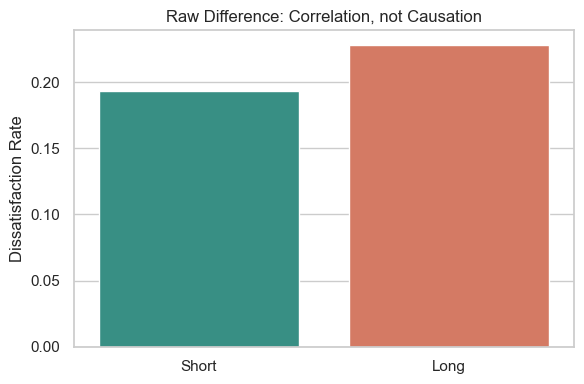

In [4]:
group_table = df_model.groupby('long_distance')['is_dissatisfied'].agg(['mean', 'count'])
group_table.index = ['Short distance (0)', 'Long distance (1)']
display(group_table)

plt.figure(figsize=(6, 4))
sns.barplot(x=['Short', 'Long'], y=group_table['mean'].values, palette=['#2a9d8f', '#e76f51'])
plt.ylabel('Dissatisfaction Rate')
plt.title('Raw Difference: Correlation, not Causation')
plt.tight_layout()
plt.show()

## Step 4: Build a Causal Graph (DAG)
The DAG encodes our assumptions: confounders affect both treatment and outcome.

In [5]:
if not DOWHY_AVAILABLE:
    raise ImportError('DoWhy is not installed. Run: %pip install dowhy')

causal_graph = '''
digraph {
    long_distance -> is_dissatisfied;

    product_weight_g -> long_distance;
    product_weight_g -> is_dissatisfied;

    price -> long_distance;
    price -> is_dissatisfied;

    freight_value -> long_distance;
    freight_value -> is_dissatisfied;

    seller_speed_days -> long_distance;
    seller_speed_days -> is_dissatisfied;

    seller_total_orders -> long_distance;
    seller_total_orders -> is_dissatisfied;

    n_items -> long_distance;
    n_items -> is_dissatisfied;

    north_order -> long_distance;
    north_order -> is_dissatisfied;
}
'''

print(causal_graph)


digraph {
    long_distance -> is_dissatisfied;

    product_weight_g -> long_distance;
    product_weight_g -> is_dissatisfied;

    price -> long_distance;
    price -> is_dissatisfied;

    freight_value -> long_distance;
    freight_value -> is_dissatisfied;

    seller_speed_days -> long_distance;
    seller_speed_days -> is_dissatisfied;

    seller_total_orders -> long_distance;
    seller_total_orders -> is_dissatisfied;

    n_items -> long_distance;
    n_items -> is_dissatisfied;

    north_order -> long_distance;
    north_order -> is_dissatisfied;
}



## Step 5: Identify and Estimate the Causal Effect (ATE)
We estimate the Average Treatment Effect using two methods:
- backdoor linear regression
- propensity score matching

In [6]:
model = CausalModel(
    data=df_model,
    treatment='long_distance',
    outcome='is_dissatisfied',
    common_causes=confounders,
    graph=causal_graph
)

identified_estimand = model.identify_effect(proceed_when_unidentifiable=True)
print('Identified estimand:')
print(identified_estimand)

estimate_lr = model.estimate_effect(
    identified_estimand,
    method_name='backdoor.linear_regression'
)

estimate_psm = model.estimate_effect(
    identified_estimand,
    method_name='backdoor.propensity_score_matching'
)

print('\nATE (Linear Regression):', round(float(estimate_lr.value), 4))
print('ATE (Propensity Score Matching):', round(float(estimate_psm.value), 4))

Identified estimand:
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
       d                                                                       ↪
────────────────(E[is_dissatisfied|n_items,product_weight_g,freight_value,pric ↪
d[long_distance]                                                               ↪

↪                                                      
↪ e,north_order,seller_total_orders,seller_speed_days])
↪                                                      
Estimand assumption 1, Unconfoundedness: If U→{long_distance} and U→is_dissatisfied then P(is_dissatisfied|long_distance,n_items,product_weight_g,freight_value,price,north_order,seller_total_orders,seller_speed_days,U) = P(is_dissatisfied|long_distance,n_items,product_weight_g,freight_value,price,north_order,seller_total_orders,seller_speed_days)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No 

## Step 6: Refutation Checks (Very Important)
These tests do not prove causality perfectly, but they improve confidence in your estimate.

In [7]:
refute_random = model.refute_estimate(
    identified_estimand,
    estimate_psm,
    method_name='random_common_cause'
)

refute_placebo = model.refute_estimate(
    identified_estimand,
    estimate_psm,
    method_name='placebo_treatment_refuter'
)

print('Random Common Cause Refuter:')
print(refute_random)
print('\nPlacebo Treatment Refuter:')
print(refute_placebo)

Random Common Cause Refuter:
Refute: Add a random common cause
Estimated effect:0.015211309555468093
New effect:0.01521130955546809
p value:1.0


Placebo Treatment Refuter:
Refute: Use a Placebo Treatment
Estimated effect:0.015211309555468093
New effect:7.839674924741248e-05
p value:0.8799999999999999



## Step 7: Explain in Plain English
Interpretation template for report/presentation:

In [8]:
ate = float(estimate_psm.value)
ate_pp = ate * 100

print('Causal interpretation (using PSM ATE):')
if ate >= 0:
    print(f'Long-distance shipping increases dissatisfaction by about {ate_pp:.2f} percentage points, on average, after controlling for key confounders.')
else:
    print(f'Long-distance shipping decreases dissatisfaction by about {abs(ate_pp):.2f} percentage points, on average, after controlling for key confounders.')

print('\nImportant assumptions to mention:')
print('- No major unobserved confounder is missing')
print('- DAG structure is approximately correct')
print('- Enough overlap exists between short and long distance groups')

Causal interpretation (using PSM ATE):
Long-distance shipping increases dissatisfaction by about 1.52 percentage points, on average, after controlling for key confounders.

Important assumptions to mention:
- No major unobserved confounder is missing
- DAG structure is approximately correct
- Enough overlap exists between short and long distance groups


### What this result means (in simple words)

 We compared two similar groups of orders:

- **Short-distance shipping** orders  
- **Long-distance shipping** orders

After adjusting for other factors (like product weight, price, freight cost, seller speed, seller size, number of items, and north-region indicator), the model estimates:

- Long-distance shipping causes about **+1.52 percentage points** higher dissatisfaction.

So this is not just a raw correlation. It suggests that **distance itself likely has a real negative effect** on customer satisfaction.

---

### Easy business interpretation

If two orders are similar in all important observed ways, but one travels a long distance and the other does not, the long-distance one is more likely to get a bad review by about **1.52%** on average.

Example:
- If dissatisfaction is around 20%, long-distance shipping would raise it to about **21.52%** (on average).

---

### Why we still call it an estimate (not absolute truth)

This conclusion depends on assumptions:

1. **No major missing confounder**  
    We assumed we included the key variables that affect both distance and dissatisfaction.

2. **DAG is roughly correct**  
    The cause-effect directions in the graph should be reasonably true.

3. **Good overlap between groups**  
    We need enough comparable short- and long-distance orders so matching/regression is fair.

If these assumptions are reasonably valid, this estimate is credible and useful for decision-making.

## Step 8: Version 2 (Implemented)

This section adds the advanced extension directly:

- **Continuous treatment:** use `distance_km` instead of a binary split
- **Heterogeneous effects:** estimate whether the effect varies by **region** and **product category**
- **Sensitivity analysis:** check how robust the result is to hidden confounding

### What this cell does
1. Preprocesses data for continuous-treatment causal modeling
2. Fits an EconML model (`CausalForestDML`)
3. Estimates subgroup effects (state and product category)
4. Runs hidden-confounding sensitivity checks with DoWhy

In [9]:
pip install econml --quiet

Note: you may need to restart the kernel to use updated packages.


EconML available: True
Rows for EconML: 94009
Confounders for EconML: ['product_weight_g', 'price', 'freight_value', 'seller_speed_days', 'seller_total_orders', 'n_items', 'north_order']

--- Continuous Treatment Effect (EconML) ---
Average marginal effect per +1 km: 0.000021
Average effect per +100 km: 0.0021 (probability points in absolute units)

Top states by estimated effect (min 200 rows):


,avg_cate_per_100km,n
customer_state,,
AL,0.002687,389
MA,0.002582,699
PB,0.002557,498
RO,0.002557,234
RN,0.002552,463
SE,0.002367,331
PI,0.002358,461
TO,0.002321,268
BA,0.002292,3170


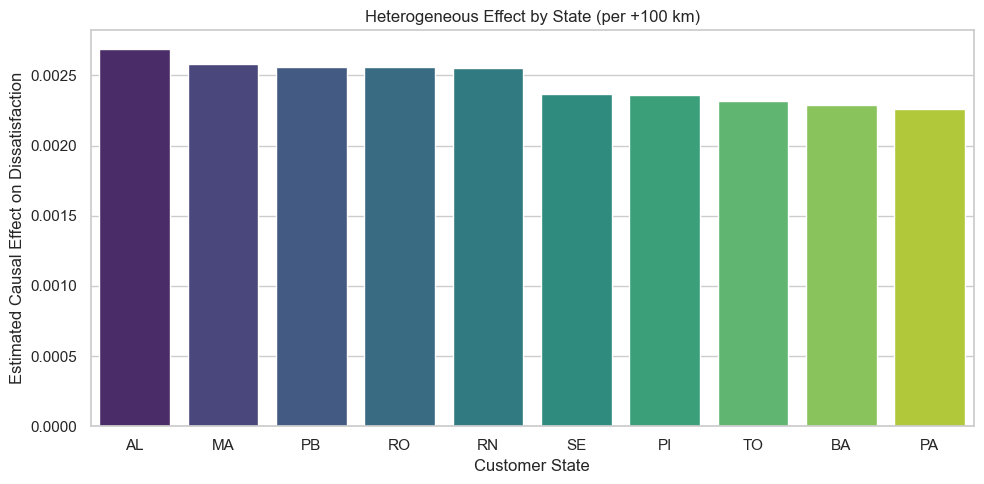


Top product categories by estimated effect (min 300 rows):


,avg_cate_per_100km,n
product_category_name,,
consoles_games,0.003708,1001
instrumentos_musicais,0.003393,600
moveis_sala,0.003014,368
moveis_escritorio,0.002998,1230
pet_shop,0.002871,1656
eletroportateis,0.002847,601
fashion_bolsas_e_acessorios,0.002789,1796
bebes,0.002591,2733
malas_acessorios,0.002549,1000


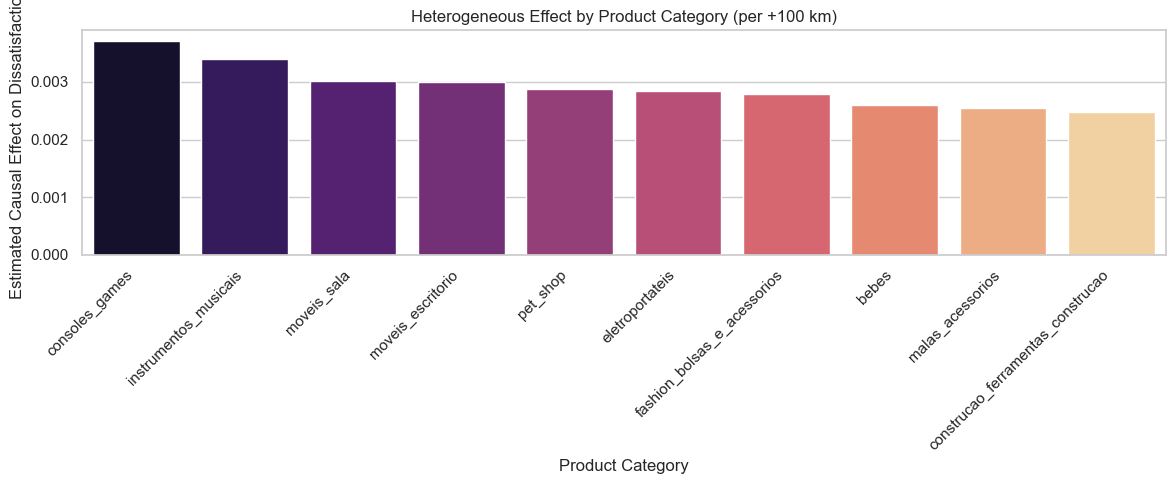


--- Hidden Confounding Sensitivity (DoWhy) ---


,strength,original_effect,new_effect
0,0.02,0.015211,0.030072
1,0.05,0.015211,0.045996
2,0.10,0.015211,0.048070
3,0.20,0.015211,0.041719
4,0.30,0.015211,0.033933


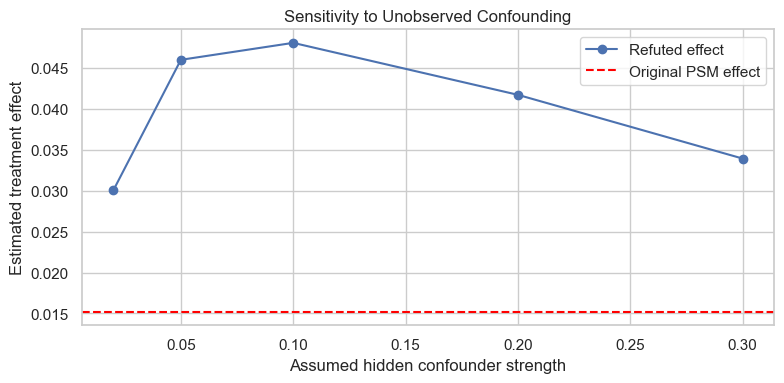

Interpretation: Effect direction stays stable across tested strengths.


In [10]:
# -----------------------------
# Version 2: Advanced Causal Extension
# -----------------------------
# If needed, install EconML once, then restart kernel:
# %pip install econml

from sklearn.ensemble import RandomForestRegressor

try:
    from econml.dml import CausalForestDML
    ECONML_AVAILABLE = True
except ImportError:
    ECONML_AVAILABLE = False

print('EconML available:', ECONML_AVAILABLE)

# We reuse df, confounders, model, identified_estimand, and estimate_psm from earlier steps.
required_cols = ['distance_km', 'is_dissatisfied']
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise ValueError(f'Missing required columns for Version 2: {missing_required}')

econ_confounders = [c for c in confounders if c in df.columns]
if len(econ_confounders) == 0:
    raise ValueError('No valid confounders found for EconML model.')

group_cols = [c for c in ['customer_state', 'product_category_name'] if c in df.columns]
econ_cols = required_cols + econ_confounders + group_cols
df_econ = df[econ_cols].copy()

# Ensure numeric columns are clean
for c in required_cols + econ_confounders:
    df_econ[c] = pd.to_numeric(df_econ[c], errors='coerce')

df_econ = df_econ.dropna(subset=['distance_km', 'is_dissatisfied'])
for c in econ_confounders:
    df_econ[c] = df_econ[c].fillna(df_econ[c].median())

X = df_econ[econ_confounders].astype(float)
T = df_econ['distance_km'].astype(float)
Y = df_econ['is_dissatisfied'].astype(float)

print('Rows for EconML:', len(df_econ))
print('Confounders for EconML:', econ_confounders)

if not ECONML_AVAILABLE:
    print('EconML is not installed. Install with: %pip install econml')
else:
    # Continuous treatment causal model
    econ_model = CausalForestDML(
        model_y=RandomForestRegressor(n_estimators=200, min_samples_leaf=10, random_state=42, n_jobs=-1),
        model_t=RandomForestRegressor(n_estimators=200, min_samples_leaf=10, random_state=42, n_jobs=-1),
        n_estimators=500,
        min_samples_leaf=20,
        random_state=42,
        discrete_treatment=False
    )

    econ_model.fit(Y=Y, T=T, X=X)

    # For continuous treatment, use marginal effect: change in dissatisfaction for +1 km
    marginal_effect = np.ravel(econ_model.const_marginal_effect(X))
    avg_marginal = float(np.mean(marginal_effect))
    avg_effect_100km = avg_marginal * 100

    print('\n--- Continuous Treatment Effect (EconML) ---')
    print(f'Average marginal effect per +1 km: {avg_marginal:.6f}')
    print(f'Average effect per +100 km: {avg_effect_100km:.4f} (probability points in absolute units)')

    # -----------------------------
    # Heterogeneous Effects
    # -----------------------------
    te_df = df_econ.copy()
    te_df['cate_per_100km'] = marginal_effect * 100

    if 'customer_state' in te_df.columns:
        state_eff = (
            te_df.groupby('customer_state')['cate_per_100km']
            .agg(['mean', 'count'])
            .rename(columns={'mean': 'avg_cate_per_100km', 'count': 'n'})
            .query('n >= 200')
            .sort_values('avg_cate_per_100km', ascending=False)
        )
        print('\nTop states by estimated effect (min 200 rows):')
        display(state_eff.head(10))

        if len(state_eff) > 0:
            plt.figure(figsize=(10, 5))
            sns.barplot(
                x=state_eff.head(10).index,
                y=state_eff.head(10)['avg_cate_per_100km'],
                palette='viridis'
            )
            plt.title('Heterogeneous Effect by State (per +100 km)')
            plt.xlabel('Customer State')
            plt.ylabel('Estimated Causal Effect on Dissatisfaction')
            plt.tight_layout()
            plt.show()

    if 'product_category_name' in te_df.columns:
        cat_eff = (
            te_df.groupby('product_category_name')['cate_per_100km']
            .agg(['mean', 'count'])
            .rename(columns={'mean': 'avg_cate_per_100km', 'count': 'n'})
            .query('n >= 300')
            .sort_values('avg_cate_per_100km', ascending=False)
        )
        print('\nTop product categories by estimated effect (min 300 rows):')
        display(cat_eff.head(10))

        if len(cat_eff) > 0:
            plt.figure(figsize=(12, 5))
            sns.barplot(
                x=cat_eff.head(10).index,
                y=cat_eff.head(10)['avg_cate_per_100km'],
                palette='magma'
            )
            plt.title('Heterogeneous Effect by Product Category (per +100 km)')
            plt.xlabel('Product Category')
            plt.ylabel('Estimated Causal Effect on Dissatisfaction')
            plt.xticks(rotation=45, ha='right')
            plt.tight_layout()
            plt.show()

# -----------------------------
# Sensitivity Analysis: Hidden Confounding
# -----------------------------
print('\n--- Hidden Confounding Sensitivity (DoWhy) ---')
strength_grid = [0.02, 0.05, 0.10, 0.20, 0.30]
sens_rows = []

for s in strength_grid:
    try:
        ref_unobs = model.refute_estimate(
            identified_estimand,
            estimate_psm,
            method_name='add_unobserved_common_cause',
            confounders_effect_on_treatment='binary_flip',
            confounders_effect_on_outcome='binary_flip',
            effect_strength_on_treatment=s,
            effect_strength_on_outcome=s
        )
        sens_rows.append({
            'strength': s,
            'original_effect': float(estimate_psm.value),
            'new_effect': float(ref_unobs.new_effect)
        })
    except Exception as e:
        sens_rows.append({
            'strength': s,
            'original_effect': float(estimate_psm.value),
            'new_effect': np.nan,
            'error': str(e)
        })

sens_df = pd.DataFrame(sens_rows)
display(sens_df)

ok_df = sens_df.dropna(subset=['new_effect']).copy()
if len(ok_df) > 0:
    plt.figure(figsize=(8, 4))
    plt.plot(ok_df['strength'], ok_df['new_effect'], marker='o', label='Refuted effect')
    plt.axhline(float(estimate_psm.value), color='red', linestyle='--', label='Original PSM effect')
    plt.xlabel('Assumed hidden confounder strength')
    plt.ylabel('Estimated treatment effect')
    plt.title('Sensitivity to Unobserved Confounding')
    plt.legend()
    plt.tight_layout()
    plt.show()

    same_sign = np.all(np.sign(ok_df['new_effect']) == np.sign(float(estimate_psm.value)))
    if same_sign:
        print('Interpretation: Effect direction stays stable across tested strengths.')
    else:
        print('Interpretation: Effect direction changes at some strengths, so conclusion is sensitive.')
else:
    print('Sensitivity refuter did not return numeric effects for this setup.')